# Fine-tuning results: experiments A, B and C (iTransformer)

This notebook computes all the results of the fine-tuning experiments for ONE transfer
direction (source greenhouse -> destination greenhouse), chosen in the configuration cell:

- **Experiment A**: fine-tuning convergence curve (epochs needed).
- **Experiment B**: learning curve (performance vs amount of fine-tuning data).
- **Experiment C**: comparison between same greenhouse, zero-shot transfer and fine-tuning.

It only READS the results already generated by the experiment scripts (CSV for A and B,
JSON for C). It must be run from the `./metrics` directory at the project root. Figures are
only displayed in the notebook, they are not saved to disk.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.dpi"] = 110

## 1. Configuration

Change `SOURCE_GREENHOUSE` / `DESTINATION_GREENHOUSE` to switch the transfer direction
(`"alava"` -> `"cartagena"` or `"cartagena"` -> `"alava"`). Every path and label in the
notebook is derived from these two variables.

In [2]:
SOURCE_GREENHOUSE = "alava"
DESTINATION_GREENHOUSE = "cartagena"

GREENHOUSE_LABELS = {
    "alava": "Álava",
    "cartagena": "Cartagena",
}
source_label = GREENHOUSE_LABELS[SOURCE_GREENHOUSE]
destination_label = GREENHOUSE_LABELS[DESTINATION_GREENHOUSE]

# The notebook runs from ./metrics, so the project root is one level up.
PROJECT_ROOT = Path("..")
RESULTS_DIR = PROJECT_ROOT / "results" / "finetuning" / f"{SOURCE_GREENHOUSE}_to_{DESTINATION_GREENHOUSE}"
CSV_DIR = RESULTS_DIR / "csv"

# Folder with the experiment C JSON files for each target
TARGET_DIRS = {
    "DB_TEMP_INT": RESULTS_DIR / "temperature",
    "REL_HUM_INT": RESULTS_DIR / "rel_humidity",
}

UNITS = {
    "DB_TEMP_INT": "°C",
    "REL_HUM_INT": "%RH",
}

print(f"Direction: {source_label} -> {destination_label}")
print(f"Results folder: {RESULTS_DIR.resolve()}")

Direction: Álava -> Cartagena
Results folder: C:\Users\jclps\Documents\DL-Study-for-Indoor-Climate-Prediction-and-Greenhouse-Generalization-in-Smart-Greenhouses\results\finetuning\alava_to_cartagena


## 2. Plot style

`FIGSIZE=(9, 5.5)`, axis labels at size 16, ticks/legend at size 15/10 and a soft dashed grid.
`apply_style()` is called at the end of every plot so they are all consistent.

In [3]:
FIGSIZE = (9, 5.5)
FS_AXES = 16
FS_TICKS = 15


def apply_style(ax, title=None, xlabel=None, ylabel=None, legend_title=None,
                fs_axes=FS_AXES, fs_ticks=FS_TICKS):
    # Titles are intentionally not drawn (they go in the figure caption).
    if xlabel is not None:
        ax.set_xlabel(xlabel, fontsize=fs_axes, labelpad=14)
    if ylabel is not None:
        ax.set_ylabel(ylabel, fontsize=fs_axes, labelpad=14)
    ax.tick_params(axis="both", labelsize=fs_ticks)
    ax.grid(True, linestyle="--", alpha=0.3)
    handles, _ = ax.get_legend_handles_labels()
    if handles:
        ax.legend(title=legend_title, fontsize=10)
    plt.tight_layout()

## 3. Metric used in the plots

Plots B.1, C.2 and the single-metric plot in C.4 use the `METRIC` variable in this cell.
Available options: `rmse`, `mae`, `mse`, `r2`, `mape`. All of them are in actual units
(degrees, %RH...), not in the normalized scale.

Mind the direction: for `rmse`, `mae`, `mse` and `mape` **lower is better**; for `r2`
**higher is better** (the closer to 1).

In [4]:
METRIC = "mae"  # <-- change here: "rmse", "mae", "mse", "r2", "mape"

METRICS = ["r2", "mse", "rmse", "mae", "mape"]
METRIC_LABELS = {
    "rmse": "RMSE",
    "mae": "MAE",
    "mse": "MSE",
    "r2": "R\u00b2",
    "mape": "MAPE (%)",
}
metric_label = METRIC_LABELS.get(METRIC, METRIC.upper())
print(f"Using metric: {METRIC} ({metric_label})")


def metric_axis_label(metric, target):
    # Axis label for a metric with the right unit for the target.
    unit = UNITS.get(target, "")
    if metric == "r2":
        return "R\u00b2"                          # dimensionless
    if metric == "mape":
        return "MAPE (%)"                          # already a percentage
    if metric == "mse":
        return f"MSE ({unit}\u00b2)" if unit else "MSE"   # squared unit
    return f"{metric.upper()} ({unit})" if unit else metric.upper()  # rmse, mae

Using metric: mae (MAE)


## 4. Experiment A - Convergence curve

### Load the CSV

In [5]:
df_hist = pd.read_csv(CSV_DIR / "experiment_A_history.csv")

print("Experiment A - history:", df_hist.shape, "| seeds:", sorted(df_hist["seed"].unique().tolist()))
df_hist.head()

Experiment A - history: (150, 5) | seeds: [0]


,seed,epoch,train_loss,val_loss,estimated_convergence_epoch
0,0,1,0.003,0.003,46
1,0,2,0.003,0.003,46
2,0,3,0.003,0.003,46
3,0,4,0.003,0.003,46
4,0,5,0.003,0.003,46


### A.1 - All curves overlaid (one line per seed)

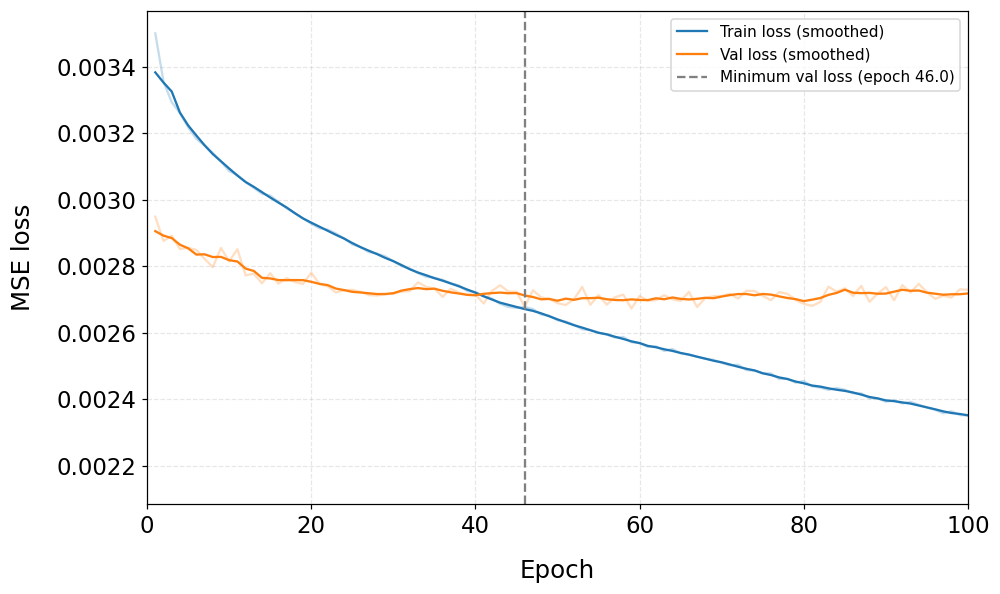

In [6]:
SMOOTHING_WINDOW = 5   # moving average size, in epochs
EPOCH_MIN = 0          # first epoch to show (None = from the start)
EPOCH_MAX = 100        # last epoch to show (None = until the end)

fig, ax = plt.subplots(figsize=FIGSIZE)

for seed, g in df_hist.groupby("seed"):
    g = g.sort_values("epoch")
    train_smooth = g["train_loss"].rolling(SMOOTHING_WINDOW, center=True, min_periods=1).mean()
    val_smooth = g["val_loss"].rolling(SMOOTHING_WINDOW, center=True, min_periods=1).mean()

    # Raw curves, semi-transparent in the background
    ax.plot(g["epoch"], g["train_loss"], color="tab:blue", alpha=0.25)
    ax.plot(g["epoch"], g["val_loss"], color="tab:orange", alpha=0.25)

    # Smoothed curves, solid on top
    ax.plot(g["epoch"], train_smooth, color="tab:blue",
            label="Train loss (smoothed)" if seed == df_hist["seed"].min() else None)
    ax.plot(g["epoch"], val_smooth, color="tab:orange",
            label="Val loss (smoothed)" if seed == df_hist["seed"].min() else None)

mean_convergence_epoch = df_hist.groupby("seed")["estimated_convergence_epoch"].first().mean()
ax.axvline(mean_convergence_epoch, color="gray", linestyle="--",
           label=f"Minimum val loss (epoch {mean_convergence_epoch:.1f})")

apply_style(ax, title=f"Fine-tuning {source_label} -> {destination_label}: convergence curve (smoothed)",
            xlabel="Epoch", ylabel="MSE loss")
ax.set_xlim(EPOCH_MIN, EPOCH_MAX)
plt.show()

## 5. Experiment B - Learning curve (amount of fine-tuning data)

### Load the CSV

In [7]:
df_b_raw = pd.read_csv(CSV_DIR / "experiment_B_raw.csv")
df_b_agg = pd.read_csv(CSV_DIR / "experiment_B_aggregated.csv")

print("Experiment B - raw:", df_b_raw.shape, "| finetune_days:", sorted(df_b_raw["finetune_days"].unique().tolist()))
print("Experiment B - aggregated:", df_b_agg.shape)

metric_columns_b = [c for c in df_b_raw.columns if c not in (
    "finetune_days", "n_train_sequences", "seed", "best_val_epoch", "epochs_run", "early_stopped"
)]
targets_b = sorted(set(c.rsplit("_", 1)[0] for c in metric_columns_b if c.endswith("_rmse")))
print("Targets detected in experiment B:", targets_b)
df_b_agg

Experiment B - raw: (138, 20) | finetune_days: [7, 14, 21, 28, 35, 42, 49, 56, 63, 70, 77, 84, 91, 98, 105, 112, 119, 126, 133, 140, 147, 154, 161, 168, 175, 182, 189, 196, 203, 210, 217, 224, 231, 238, 245, 252, 259, 266, 273, 280, 287, 294, 301, 308, 315, 322]
Experiment B - aggregated: (46, 32)
Targets detected in experiment B: ['DB_TEMP_INT', 'REL_HUM_INT']


,finetune_days,n_train_sequences,best_val_epoch_mean,best_val_epoch_std,DB_TEMP_INT_r2_mean,DB_TEMP_INT_r2_std,DB_TEMP_INT_mse_mean,DB_TEMP_INT_mse_std,DB_TEMP_INT_rmse_mean,DB_TEMP_INT_rmse_std,DB_TEMP_INT_mae_mean,DB_TEMP_INT_mae_std,DB_TEMP_INT_mape_mean,DB_TEMP_INT_mape_std,DB_TEMP_INT_relative_error_mean,DB_TEMP_INT_relative_error_std,DB_TEMP_INT_relative_error_abs_mean,DB_TEMP_INT_relative_error_abs_std,REL_HUM_INT_r2_mean,REL_HUM_INT_r2_std,REL_HUM_INT_mse_mean,REL_HUM_INT_mse_std,REL_HUM_INT_rmse_mean,REL_HUM_INT_rmse_std,REL_HUM_INT_mae_mean,REL_HUM_INT_mae_std,REL_HUM_INT_mape_mean,REL_HUM_INT_mape_std,REL_HUM_INT_relative_error_mean,REL_HUM_INT_relative_error_std,REL_HUM_INT_relative_error_abs_mean,REL_HUM_INT_relative_error_abs_std
0,7,553.000,5.000,1.000,0.891,0.000,4.912,0.020,2.216,0.005,1.451,0.003,7.387,0.053,0.013,0.003,0.074,0.001,0.847,0.002,16.728,0.204,4.090,0.025,2.055,0.008,2.539,0.008,0.002,0.001,0.025,0.000
1,14,"1,149.000",3.333,0.577,0.901,0.001,4.461,0.024,2.112,0.006,1.375,0.011,7.069,0.103,0.013,0.005,0.071,0.001,0.849,0.003,16.505,0.314,4.062,0.039,2.062,0.020,2.527,0.024,0.004,0.003,0.025,0.000
2,21,"1,778.000",2.667,0.577,0.901,0.001,4.441,0.054,2.107,0.013,1.350,0.017,6.933,0.147,0.012,0.005,0.069,0.001,0.848,0.001,16.674,0.105,4.083,0.013,1.964,0.005,2.432,0.004,0.002,0.001,0.024,0.000
3,28,"2,368.000",5.000,2.000,0.907,0.001,4.169,0.054,2.042,0.013,1.298,0.022,6.644,0.163,0.014,0.005,0.066,0.002,0.851,0.001,16.262,0.077,4.033,0.010,2.042,0.056,2.493,0.050,0.001,0.004,0.025,0.000
4,35,"3,003.000",2.667,1.155,0.909,0.001,4.085,0.052,2.021,0.013,1.281,0.011,6.560,0.095,0.013,0.004,0.066,0.001,0.853,0.002,16.127,0.250,4.016,0.031,1.918,0.020,2.372,0.017,0.003,0.002,0.024,0.000
5,42,"3,587.000",6.000,2.000,0.908,0.002,4.144,0.082,2.036,0.020,1.299,0.021,6.632,0.181,0.015,0.006,0.066,0.002,0.850,0.003,16.392,0.302,4.049,0.037,2.040,0.101,2.503,0.093,0.001,0.003,0.025,0.001
6,49,"4,228.000",20.667,10.599,0.911,0.000,4.013,0.022,2.003,0.006,1.262,0.006,6.403,0.041,0.012,0.002,0.064,0.000,0.858,0.001,15.594,0.143,3.949,0.018,1.973,0.015,2.441,0.016,0.005,0.001,0.024,0.000
7,56,"4,809.000",10.333,3.215,0.913,0.001,3.918,0.048,1.979,0.012,1.244,0.011,6.384,0.063,0.013,0.001,0.064,0.001,0.858,0.001,15.566,0.092,3.945,0.012,2.033,0.047,2.490,0.042,0.001,0.002,0.025,0.000
8,63,"5,453.000",15.000,6.245,0.914,0.000,3.889,0.017,1.972,0.004,1.237,0.007,6.334,0.043,0.011,0.002,0.063,0.000,0.859,0.003,15.483,0.333,3.935,0.042,1.941,0.037,2.406,0.036,0.003,0.002,0.024,0.000
9,70,"6,033.000",15.000,7.211,0.915,0.001,3.823,0.024,1.955,0.006,1.225,0.002,6.285,0.054,0.010,0.003,0.063,0.001,0.864,0.002,14.869,0.206,3.856,0.027,1.848,0.009,2.299,0.016,0.004,0.000,0.023,0.000


### B.1 - Performance vs amount of fine-tuning data

Uses the metric chosen in `METRIC`.

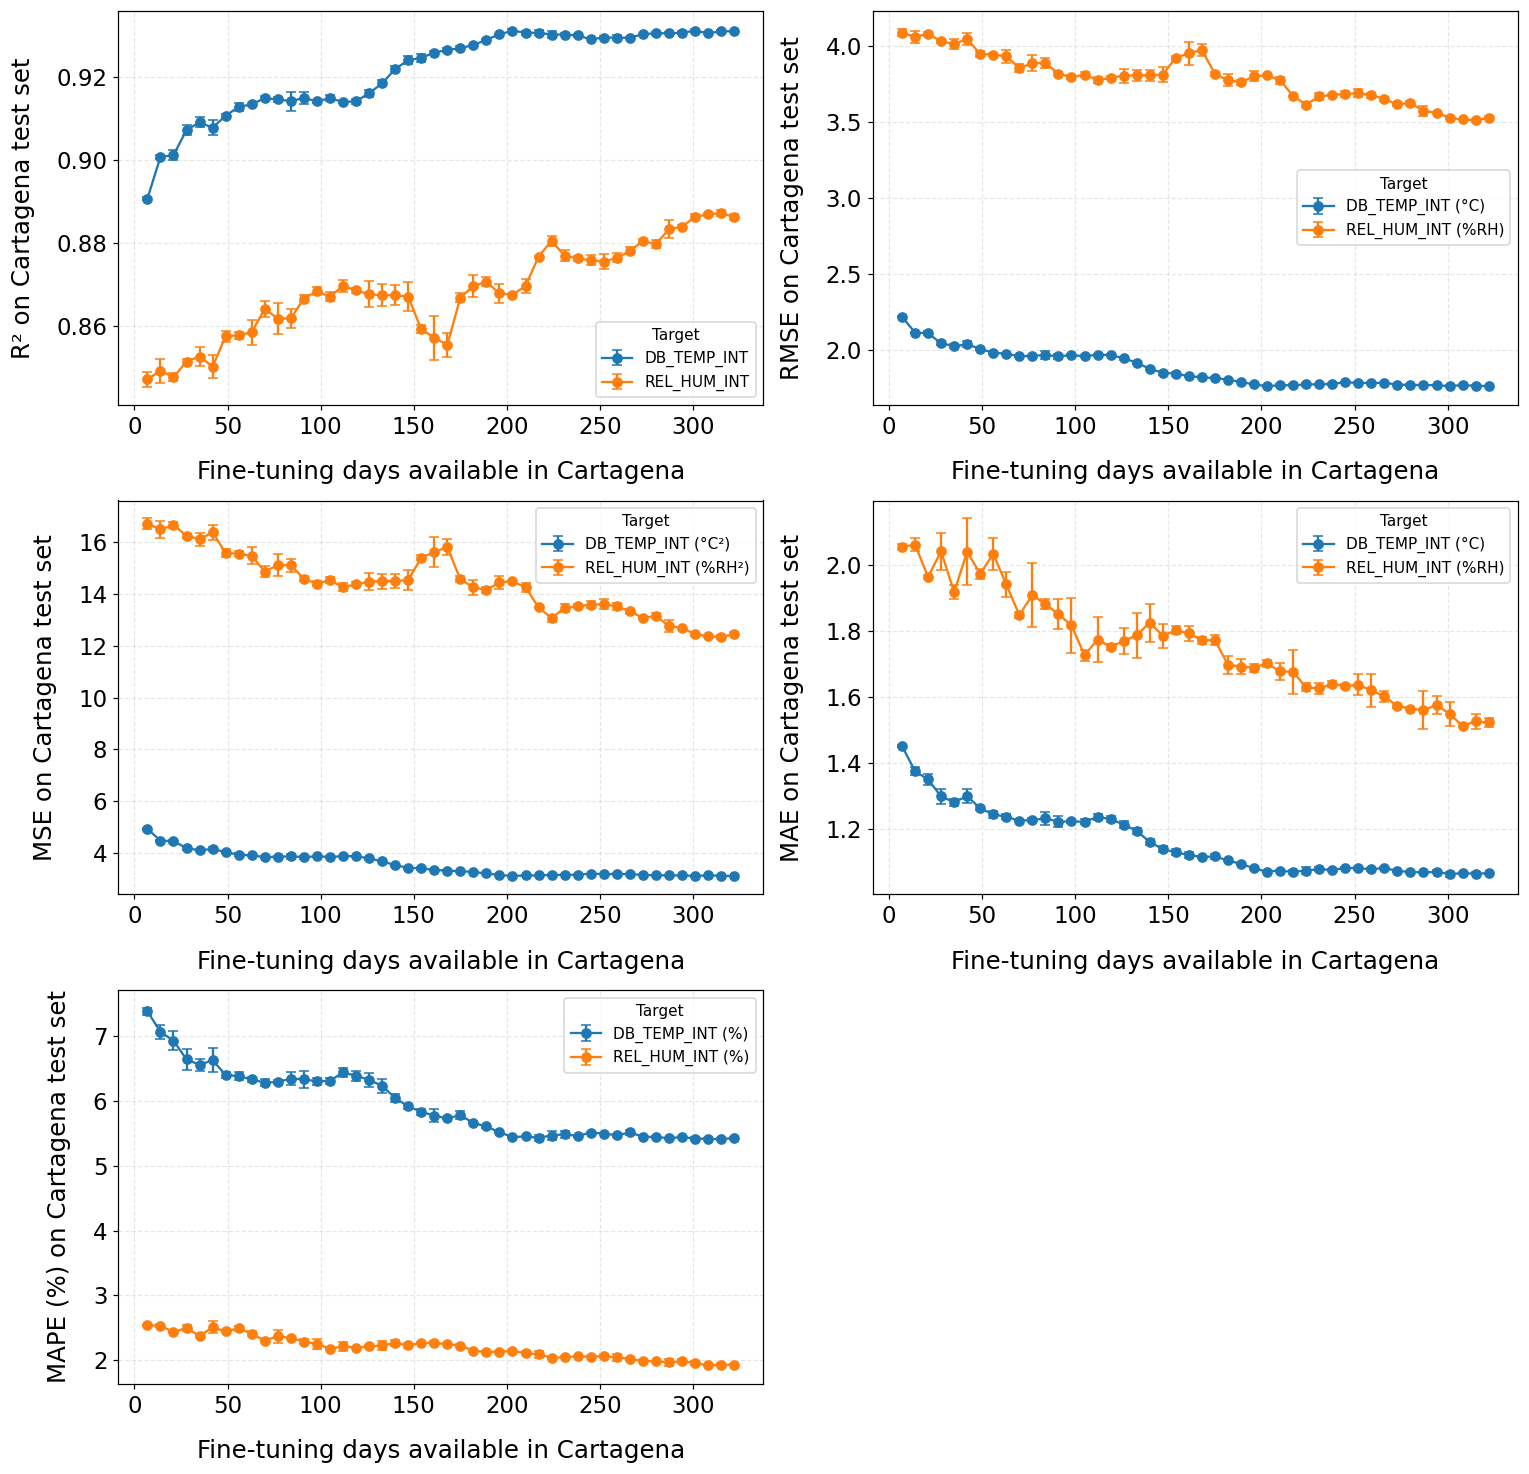

In [8]:
B_METRICS = ["r2", "rmse", "mse", "mae", "mape"]


def target_legend_label(target, metric):
    # Legend label for a target with the unit of the given metric.
    unit = UNITS.get(target, "")
    if metric == "r2" or not unit:
        return target                      # dimensionless
    if metric == "mape":
        return f"{target} (%)"             # already a percentage
    if metric == "mse":
        return f"{target} ({unit}\u00b2)"  # squared unit
    return f"{target} ({unit})"            # rmse, mae


def plot_learning_curve_all_metrics(df_b_agg, targets, metrics=B_METRICS,
                                    ncols=2, figsize=(7, 4.5)):
    """One subplot per metric in a single figure, each showing every target
    against the number of fine-tuning days (mean ± std across seeds)."""
    nrows = -(-len(metrics) // ncols)  # ceil division
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize[0] * ncols, figsize[1] * nrows))
    axes = np.array(axes).reshape(-1)

    for ax, metric in zip(axes, metrics):
        for target in targets:
            ax.errorbar(
                df_b_agg["finetune_days"],
                df_b_agg[f"{target}_{metric}_mean"],
                yerr=df_b_agg[f"{target}_{metric}_std"].fillna(0),
                marker="o", capsize=3, label=target_legend_label(target, metric),
            )
        apply_style(ax, title=f"Learning curve: {METRIC_LABELS[metric]} vs fine-tuning days",
                    xlabel=f"Fine-tuning days available in {destination_label}",
                    ylabel=f"{METRIC_LABELS[metric]} on {destination_label} test set",
                    legend_title="Target")

    # Hide unused axes if metrics don't fill the grid exactly
    for ax in axes[len(metrics):]:
        ax.set_visible(False)

    fig.tight_layout()
    return fig


plot_learning_curve_all_metrics(df_b_agg, targets_b)
plt.show()

## 6. Experiment C - Same greenhouse vs zero-shot transfer vs fine-tuning

Compares three ways of obtaining a model for the destination greenhouse:

1. **Same greenhouse**: trained and evaluated directly on the destination.
2. **Zero-shot transfer**: model trained only on the source greenhouse, evaluated on the
   destination WITHOUT any fine-tuning.
3. **Fine-tuning**: the same source model, fine-tuned on destination data.

The JSON files of each target are read from `TARGET_DIRS`. The condition is inferred from
the file name: files containing `zeroshot` are zero-shot transfer, files containing
`finetuned` are fine-tuning, and any other file is assumed to be same greenhouse. If a
same-greenhouse file name collides with this rule, add it to `MANUAL_CONDITIONS`.

In [9]:
PATTERN = "*.json"

COND_ZEROSHOT = "Zero-shot transfer"
COND_FINETUNED = "Fine-tuning"
COND_SAME = "Same greenhouse"

# Narrative order of the conditions in the plots (from expected "worst" to "best").
# Any condition not in this list is appended at the end.
CONDITION_ORDER = [COND_ZEROSHOT, COND_FINETUNED, COND_SAME]

# Manual overrides: file name (without extension) -> condition.
MANUAL_CONDITIONS = {
    # "some_same_greenhouse_file": COND_SAME,
}


def infer_condition(experiment_name):
    if experiment_name in MANUAL_CONDITIONS:
        return MANUAL_CONDITIONS[experiment_name]
    n = experiment_name.lower()
    if "finetuned" in n or "finetuning" in n:
        return COND_FINETUNED
    if "zeroshot" in n or "zero_shot" in n:
        return COND_ZEROSHOT
    return COND_SAME


def category_order(values):
    present = list(dict.fromkeys(values))  # unique values, keeps order of appearance
    return [c for c in CONDITION_ORDER if c in present] + [c for c in present if c not in CONDITION_ORDER]

### Load the JSON files

In [10]:
def load_results(directory: Path, target_variable: str, pattern: str = "*.json"):
    files = sorted(Path(directory).glob(pattern))
    data = []
    for f in files:
        with open(f, "r", encoding="utf-8") as fh:
            content = json.load(fh)
        items = content if isinstance(content, list) else [content]
        for i, d in enumerate(items):
            d = dict(d)
            d["_file"] = f.name if len(items) == 1 else f"{f.name}[{i}]"
            d["_experiment"] = f.stem
            d["_condition"] = infer_condition(f.stem)
            d["_target_variable"] = d.get("target_variable", target_variable)
            data.append(d)
    return data


data = []
for target_variable, directory in TARGET_DIRS.items():
    if not directory.exists():
        print(f"Warning: directory '{directory}' does not exist, skipping.")
        continue
    data += load_results(directory, target_variable, PATTERN)

print(f"Loaded {len(data)} result entries.")
print()
print("Detected experiments -> assigned condition:")
seen = set()
for d in data:
    key = (d["_target_variable"], d["_experiment"])
    if key in seen:
        continue
    seen.add(key)
    print(f"  [{d['_target_variable']:<14}] {d['_experiment']:<45} -> {d['_condition']}")

Loaded 18 result entries.

Detected experiments -> assigned condition:
  [DB_TEMP_INT   ] 02_itransformer_alava_cartagena_direct_comparison_finetuned -> Fine-tuning
  [DB_TEMP_INT   ] 02_itransformer_alava_cartagena_direct_comparison_same_reference -> Same greenhouse
  [DB_TEMP_INT   ] 02_itransformer_alava_cartagena_direct_comparison_zeroshot -> Zero-shot transfer
  [REL_HUM_INT   ] 02_itransformer_alava_cartagena_direct_comparison_finetuned -> Fine-tuning
  [REL_HUM_INT   ] 02_itransformer_alava_cartagena_direct_comparison_reference -> Same greenhouse
  [REL_HUM_INT   ] 02_itransformer_alava_cartagena_direct_comparison_zeroshot -> Zero-shot transfer


### Build the DataFrames

In [11]:
def build_global_df(data):
    rows = []
    for d in data:
        row = {"target_variable": d["_target_variable"], "condition": d["_condition"],
               "experiment": d["_experiment"], "file": d["_file"]}
        row.update(d["metrics"]["global"])
        rows.append(row)
    return pd.DataFrame(rows)


def build_horizon_df(data):
    rows = []
    for d in data:
        for h_key, metrics in d["metrics"].get("per_horizon", {}).items():
            row = {"target_variable": d["_target_variable"], "condition": d["_condition"],
                   "experiment": d["_experiment"], "file": d["_file"],
                   "horizon": int(h_key.split("_")[1])}
            row.update(metrics)
            rows.append(row)
    return pd.DataFrame(rows)


df_global = build_global_df(data)
df_horizon = build_horizon_df(data)
targets = sorted(df_global["target_variable"].unique())
df_global.head()

,target_variable,condition,experiment,file,r2,mse,rmse,mae,mape,relative_error,relative_error_abs
0,DB_TEMP_INT,Fine-tuning,02_itransformer_alava_cartagena_direct_compari...,02_itransformer_alava_cartagena_direct_compari...,0.926,3.314,1.820,1.076,5.458,-0.003,0.055
1,DB_TEMP_INT,Fine-tuning,02_itransformer_alava_cartagena_direct_compari...,02_itransformer_alava_cartagena_direct_compari...,0.930,3.134,1.770,1.059,5.389,0.002,0.054
2,DB_TEMP_INT,Fine-tuning,02_itransformer_alava_cartagena_direct_compari...,02_itransformer_alava_cartagena_direct_compari...,0.930,3.171,1.781,1.067,5.431,0.001,0.054
3,DB_TEMP_INT,Same greenhouse,02_itransformer_alava_cartagena_direct_compari...,02_itransformer_alava_cartagena_direct_compari...,0.927,3.306,1.818,1.066,5.383,0.006,0.054
4,DB_TEMP_INT,Same greenhouse,02_itransformer_alava_cartagena_direct_compari...,02_itransformer_alava_cartagena_direct_compari...,0.926,3.348,1.830,1.067,5.401,0.003,0.054


### C.1 - Comparison table (mean ± std per target variable x condition)

In [12]:
def mean_std_table(df, metrics, group_cols):
    agg = df.groupby(group_cols)[metrics].agg(["mean", "std"])
    out = pd.DataFrame(index=agg.index)
    for m in metrics:
        mean = agg[(m, "mean")]
        std = agg[(m, "std")].fillna(0)
        out[m] = [f"{mu:.3f} \u00b1 {sd:.3f}" for mu, sd in zip(mean, std)]
    return out


comparison_table = mean_std_table(df_global, METRICS, ["target_variable", "condition"])
comparison_table = comparison_table.reindex(
    pd.MultiIndex.from_product([
        sorted(df_global["target_variable"].unique()),
        category_order(df_global["condition"]),
    ], names=["target_variable", "condition"])
).dropna(how="all")
comparison_table

r2             mse  \
target_variable condition                                           
DB_TEMP_INT     Zero-shot transfer  0.897 ± 0.009   4.640 ± 0.426   
                Fine-tuning         0.929 ± 0.002   3.206 ± 0.095   
                Same greenhouse     0.926 ± 0.001   3.343 ± 0.035   
REL_HUM_INT     Zero-shot transfer  0.857 ± 0.007  15.711 ± 0.800   
                Fine-tuning         0.886 ± 0.002  12.430 ± 0.186   
                Same greenhouse     0.877 ± 0.003  13.479 ± 0.275   

                                             rmse            mae  \
target_variable condition                                          
DB_TEMP_INT     Zero-shot transfer  2.153 ± 0.098  1.357 ± 0.055   
                Fine-tuning         1.790 ± 0.027  1.067 ± 0.009   
                Same greenhouse     1.828 ± 0.010  1.072 ± 0.009   
REL_HUM_INT     Zero-shot transfer  3.963 ± 0.101  1.993 ± 0.038   
                Fine-tuning         3.526 ± 0.026  1.516 ± 0.039   
                Same greenhouse     3.671 ± 0.037  1.491 ± 0.048   

                                             mape  
target_variable condition                          
DB_TEMP_INT     Zero-shot transfer  6.812 ± 0.193  
                Fine-tuning         5.426 ± 0.035  
                Same greenhouse     5.403 ± 0.021  
REL_HUM_INT     Zero-shot transfer  2.448 ± 0.055  
                Fine-tuning         1.932 ± 0.039  
                Same greenhouse     1.999 ± 0.031

### C.2 - Improvement of fine-tuning over zero-shot transfer

Positive = fine-tuning improves over zero-shot transfer. For `r2` the improvement is the
difference in points (not a %, because it can cross 0); for the other metrics (where lower is
better) it is the % reduction of the error.

In [13]:
improvement_rows = []
for target in targets:
    row = {"target_variable": target}
    for metric in METRICS:
        zs = df_global[(df_global.target_variable == target) & (df_global.condition == COND_ZEROSHOT)][metric].mean()
        ft = df_global[(df_global.target_variable == target) & (df_global.condition == COND_FINETUNED)][metric].mean()
        if pd.isna(zs) or pd.isna(ft):
            continue
        if metric == "r2":
            row[f"improvement_{metric}_pp"] = ft - zs
        else:
            row[f"improvement_{metric}_pct"] = 100 * (zs - ft) / zs
    improvement_rows.append(row)

pd.DataFrame(improvement_rows).set_index("target_variable")

,improvement_r2_pp,improvement_mse_pct,improvement_rmse_pct,improvement_mae_pct,improvement_mape_pct
target_variable,,,,,
DB_TEMP_INT,0.032,30.906,16.826,21.370,20.341
REL_HUM_INT,0.030,20.884,11.035,23.944,21.064


### C.3 - Evolution per prediction horizon, per condition

`plot_metric_per_horizon()` draws one metric for one target, with one line per condition
(mean ± std across repetitions).

In [14]:
def plot_metric_per_horizon(df_horizon, target, metric="r2", ax=None, title=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=FIGSIZE)

    sub_target = df_horizon[df_horizon["target_variable"] == target]
    for cond in category_order(sub_target["condition"]):
        sub = sub_target[sub_target["condition"] == cond]
        agg = sub.groupby("horizon")[metric].agg(["mean", "std"]).sort_index()
        ax.plot(agg.index, agg["mean"], marker="o", markersize=3, label=cond)
        std = agg["std"].fillna(0)
        if (std > 0).any():
            ax.fill_between(agg.index, agg["mean"] - std, agg["mean"] + std, alpha=0.15)

    apply_style(ax, title=title or f"{target}: {metric.upper()} evolution per horizon",
                xlabel="Prediction horizon (15-min steps)",
                ylabel=metric_axis_label(metric, target),
                legend_title="Condition")
    return ax

#### Metric chosen in `METRIC`

In [15]:
# for target in targets:
#     fig, ax = plt.subplots(figsize=FIGSIZE)
#     plot_metric_per_horizon(df_horizon, target, metric=METRIC, ax=ax)
#     fig.tight_layout()
#     plt.show()

#### All metrics per horizon (one figure per target: first image temperature and second relative humidity)

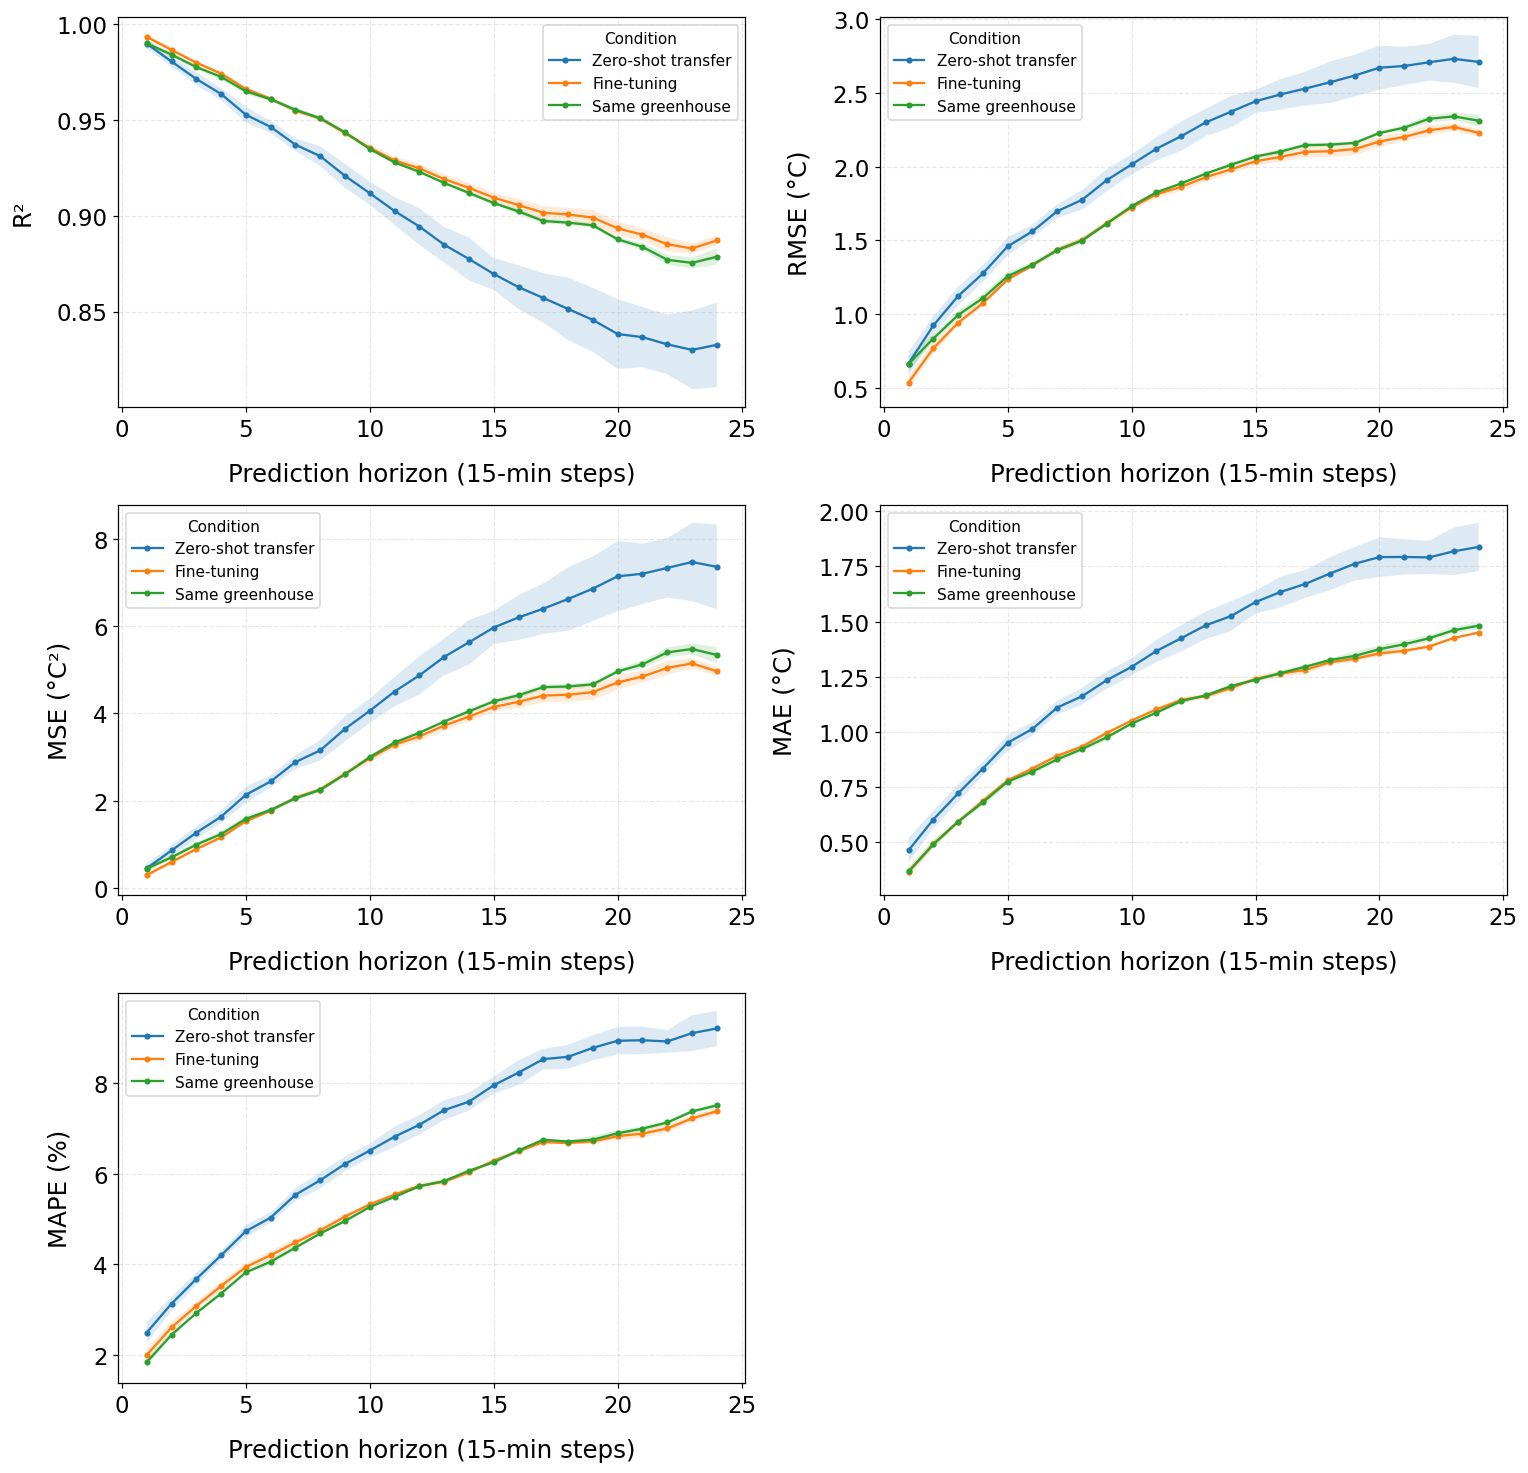

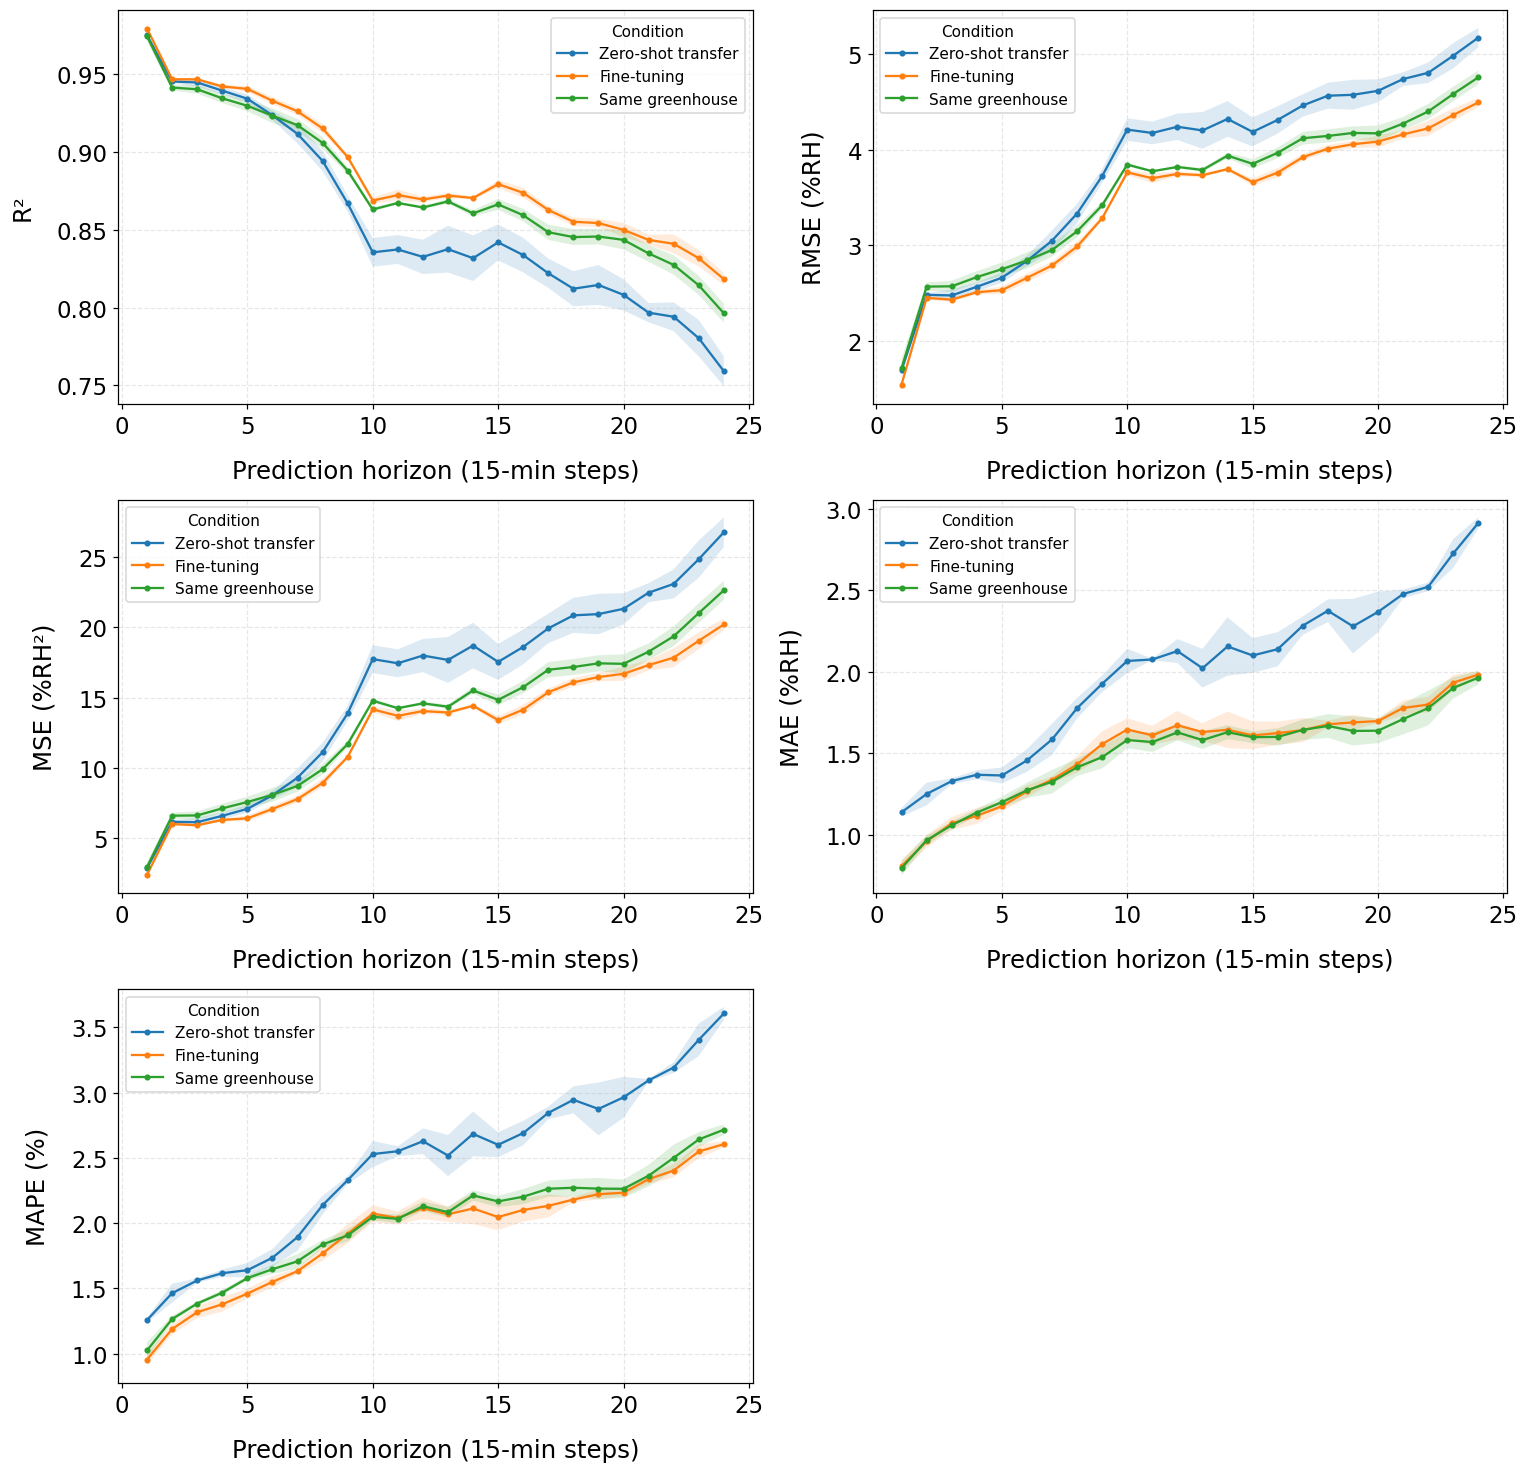

In [16]:
HORIZON_METRICS = ["r2", "rmse", "mse", "mae", "mape"]


def plot_all_metrics_per_horizon(df_horizon, target, metrics=HORIZON_METRICS,
                                 ncols=2, figsize=(7, 4.5)):
    """Draws one subplot per metric for a single target, each showing every
    condition, in a single figure."""
    nrows = -(-len(metrics) // ncols)  # ceil division
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize[0] * ncols, figsize[1] * nrows))
    axes = np.array(axes).reshape(-1)

    for ax, metric in zip(axes, metrics):
        plot_metric_per_horizon(df_horizon, target, metric=metric, ax=ax)

    # Hide unused axes if metrics don't fill the grid exactly
    for ax in axes[len(metrics):]:
        ax.set_visible(False)

    fig.tight_layout()
    return fig


for target in targets:
    plot_all_metrics_per_horizon(df_horizon, target)
    plt.show()